# 02 · Logistic Regression — From Lines to Probabilities

**Problem type:** supervised **classification** (predict a category).

**What you'll learn**
1. Why linear regression fails for yes/no questions
2. The **sigmoid** function: squashing any number into a probability
3. The **log-loss** (cross-entropy) and why we don't use MSE here
4. Training with gradient descent — 🐍 pure Python → 🔢 NumPy → 📦 scikit-learn
5. **Decision boundaries**, thresholds, and multi-class with **softmax**

Despite the name, logistic regression is a **classification** algorithm. It's the workhorse baseline of industry — and a single neuron of a neural network (notebook 07).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

## 1. The problem with lines for yes/no

Hours studied → pass (1) or fail (0). A straight line predicts values like −0.3 or 1.4, which aren't probabilities, and one extreme point drags the whole line around. We need a function whose output always stays **between 0 and 1**.

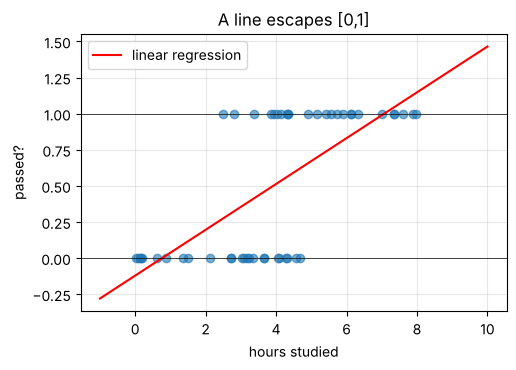

In [2]:
hours = np.concatenate([rng.uniform(0, 5, 25), rng.uniform(2, 8, 25)])
passed = np.concatenate([np.zeros(25), np.ones(25)])

w, b = np.polyfit(hours, passed, 1)
xs = np.linspace(-1, 10, 200)
plt.scatter(hours, passed, alpha=0.6)
plt.plot(xs, w * xs + b, "r", label="linear regression")
plt.axhline(0, c="k", lw=0.5); plt.axhline(1, c="k", lw=0.5)
plt.xlabel("hours studied"); plt.ylabel("passed?"); plt.legend(); plt.title("A line escapes [0,1]"); plt.show()

## 2. The sigmoid function

$$ \sigma(z) = \frac{1}{1 + e^{-z}} $$

- Large positive z → σ ≈ 1. Large negative z → σ ≈ 0. z = 0 → σ = 0.5.
- **Logistic regression = linear model + sigmoid:**

$$ P(y=1 \mid x) = \sigma(w \cdot x + b) $$

The linear part $z = w\cdot x + b$ is called the **logit** or **log-odds**: $z = \log\frac{p}{1-p}$. So each weight says "one unit more of this feature multiplies the *odds* by $e^{w}$."

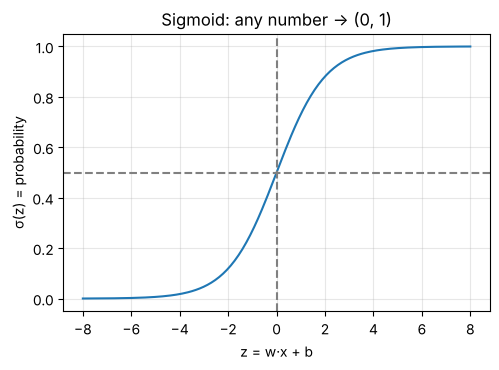

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z)); plt.axhline(0.5, ls="--", c="gray"); plt.axvline(0, ls="--", c="gray")
plt.xlabel("z = w·x + b"); plt.ylabel("σ(z) = probability"); plt.title("Sigmoid: any number → (0, 1)"); plt.show()

## 3. The loss: log-loss (binary cross-entropy)

If the true label is 1, we want $p$ close to 1; if 0, $p$ close to 0. The loss for one example:

$$ \ell = -\big[\, y \log p + (1-y)\log(1-p) \,\big] $$

- y=1: loss = −log p → 0 when p→1, **∞ when p→0** (confidently wrong = punished hard)
- y=0: loss = −log(1−p)

**Why not MSE?** With a sigmoid inside, MSE makes the loss landscape non-convex (bumpy) and gives tiny gradients when the model is confidently wrong. Log-loss is convex and comes straight from **maximum likelihood** — it's the "natural" loss for probabilities.

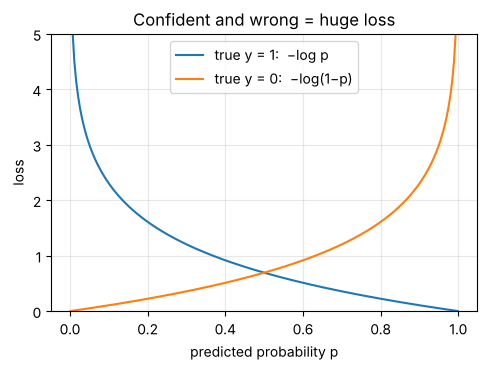

In [4]:
p = np.linspace(0.001, 0.999, 200)
plt.plot(p, -np.log(p), label="true y = 1:  −log p")
plt.plot(p, -np.log(1 - p), label="true y = 0:  −log(1−p)")
plt.xlabel("predicted probability p"); plt.ylabel("loss"); plt.ylim(0, 5); plt.legend()
plt.title("Confident and wrong = huge loss"); plt.show()

## 4. Training with gradient descent

A beautiful fact: the gradient of log-loss through a sigmoid simplifies to

$$ \frac{\partial \ell}{\partial w} = (p - y)\,x, \qquad \frac{\partial \ell}{\partial b} = (p - y) $$

— *prediction minus truth, times the input*. That's exactly the same form as linear regression's gradient. (The derivation: $\sigma'(z) = \sigma(z)(1-\sigma(z))$ cancels the denominators in the log-loss derivative. It's in `DL_Interview_Notes.md` §1.2.)

In [5]:
# 🐍 Pure Python logistic regression (works for any number of features)
import math

def sigmoid_py(z):
    # numerically safe version: avoids overflow in exp for very negative z
    if z >= 0:
        return 1 / (1 + math.exp(-z))
    ez = math.exp(z)
    return ez / (1 + ez)

def logreg_fit_python(X, y, lr=0.1, epochs=2000):
    n, d = len(X), len(X[0])
    w, b = [0.0] * d, 0.0
    for _ in range(epochs):
        dw, db = [0.0] * d, 0.0
        for xi, yi in zip(X, y):
            p = sigmoid_py(sum(wj * xj for wj, xj in zip(w, xi)) + b)
            err = p - yi                          # prediction − truth
            for j in range(d):
                dw[j] += err * xi[j] / n
            db += err / n
        w = [wj - lr * g for wj, g in zip(w, dw)]
        b -= lr * db
    return w, b

def logreg_predict_proba_python(X, w, b):
    return [sigmoid_py(sum(wj * xj for wj, xj in zip(w, xi)) + b) for xi in X]

w_py, b_py = logreg_fit_python([[h] for h in hours], passed.tolist(), epochs=20000)
print(f"pure Python: w = {w_py[0]:.3f}, b = {b_py:.3f}")
print(f"decision boundary (p = 0.5) at {-b_py / w_py[0]:.2f} hours")

pure Python: w = 1.350, b = -5.327
decision boundary (p = 0.5) at 3.95 hours


NumPy:       w = 1.350, b = -5.327


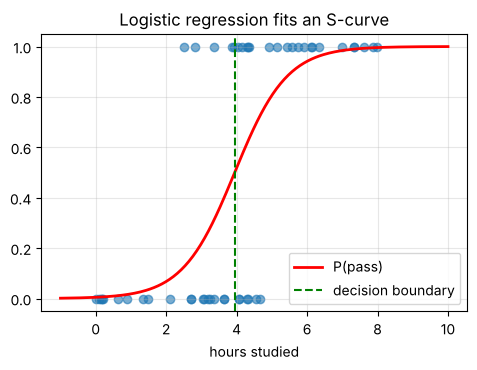

In [6]:
# 🔢 NumPy version — the whole dataset in one matrix operation
class LogisticRegressionNP:
    def __init__(self, lr=0.1, epochs=2000, l2=0.0):
        self.lr, self.epochs, self.l2 = lr, epochs, l2

    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        self.losses = []
        for _ in range(self.epochs):
            p = sigmoid(X @ self.w + self.b)
            grad_w = X.T @ (p - y) / n + self.l2 * self.w     # optional L2 regularisation
            grad_b = np.mean(p - y)
            self.w -= self.lr * grad_w
            self.b -= self.lr * grad_b
            eps = 1e-12
            self.losses.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

m = LogisticRegressionNP(epochs=20000).fit(hours.reshape(-1, 1), passed)
print(f"NumPy:       w = {m.w[0]:.3f}, b = {m.b:.3f}")

plt.scatter(hours, passed, alpha=0.6)
plt.plot(xs, m.predict_proba(xs.reshape(-1, 1)), "r", lw=2, label="P(pass)")
plt.axvline(-m.b / m.w[0], ls="--", c="g", label="decision boundary")
plt.xlabel("hours studied"); plt.legend(); plt.title("Logistic regression fits an S-curve"); plt.show()

In [7]:
# 📦 scikit-learn. Note: sklearn adds L2 regularisation by default (C = 1/λ). Use a big C to match ours.
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1e6).fit(hours.reshape(-1, 1), passed)
print(f"sklearn:     w = {sk.coef_[0][0]:.3f}, b = {sk.intercept_[0]:.3f}")
print("All three agree ✔ (sklearn uses a faster solver, L-BFGS, instead of plain gradient descent)")

sklearn:     w = 1.350, b = -5.327
All three agree ✔ (sklearn uses a faster solver, L-BFGS, instead of plain gradient descent)


## 5. Two features → see the decision boundary

With 2 features, the boundary $w_1x_1 + w_2x_2 + b = 0$ is a **straight line** in the plane. Logistic regression is a **linear classifier**: one side is class 1, the other is class 0.

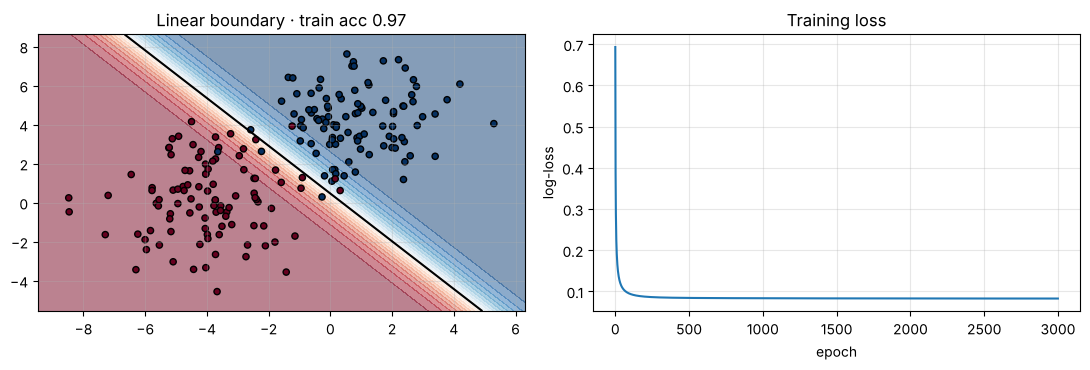

In [8]:
from sklearn.datasets import make_blobs, make_moons

def plot_boundary(model, X, y, ax=None, title=""):
    ax = ax or plt.gca()
    x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    grid = np.c_[x0.ravel(), x1.ravel()]
    P = model.predict_proba(grid)
    P = P[:, 1] if P.ndim == 2 else P
    ax.contourf(x0, x1, P.reshape(x0.shape), levels=20, cmap="RdBu_r", alpha=0.5)
    ax.contour(x0, x1, P.reshape(x0.shape), levels=[0.5], colors="k")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolor="k", s=20); ax.set_title(title)

Xb, yb = make_blobs(200, centers=2, cluster_std=1.6, random_state=3)
m2 = LogisticRegressionNP(epochs=3000).fit(Xb, yb)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
plot_boundary(m2, Xb, yb, ax[0], f"Linear boundary · train acc {np.mean(m2.predict(Xb) == yb):.2f}")
ax[1].plot(m2.losses); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("log-loss"); ax[1].set_title("Training loss")
plt.tight_layout(); plt.show()

### When the classes aren't linearly separable

A line can't separate two interlocking moons. Same trick as polynomial regression: **add non-linear features** ($x_1^2, x_1x_2, \dots$) and the boundary can curve.

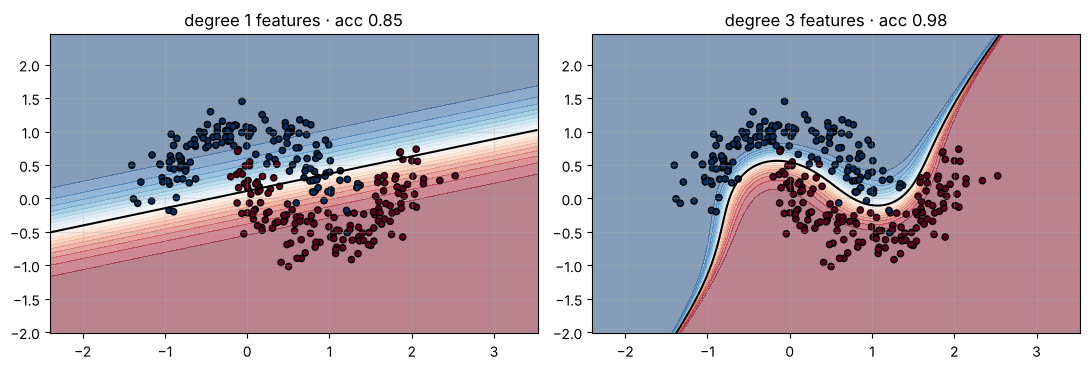

In [9]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

Xm, ym = make_moons(300, noise=0.2, random_state=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, deg in zip(ax, [1, 3]):
    clf = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LogisticRegression(C=10, max_iter=2000)).fit(Xm, ym)
    plot_boundary(clf, Xm, ym, a, f"degree {deg} features · acc {clf.score(Xm, ym):.2f}")
plt.tight_layout(); plt.show()

## 6. The threshold is a business decision

`predict` uses p ≥ 0.5 by default, but that's a choice:
- **Cancer screening:** missing a sick patient is terrible → lower the threshold (catch more, accept false alarms).
- **Spam filter:** binning a real email is terrible → raise the threshold.

In the breast-cancer data below, class **1 = benign**. Being cautious means demanding a *higher* probability before we call a tumour benign — watch the number of missed malignant tumours fall as the threshold rises, while overall accuracy barely moves.

Precision/recall and ROC curves (notebook 03) are the tools for choosing it.

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

Xc, yc = load_breast_cancer(return_X_y=True)       # 1 = benign, 0 = malignant
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)
sc = StandardScaler().fit(Xtr)
clf = LogisticRegressionNP(lr=0.5, epochs=3000, l2=0.01).fit(sc.transform(Xtr), ytr)
probs = clf.predict_proba(sc.transform(Xte))

for t in [0.2, 0.5, 0.8]:
    pred = (probs >= t).astype(int)
    missed_malignant = np.sum((yte == 0) & (pred == 1))
    print(f"threshold {t}: accuracy {np.mean(pred == yte):.3f} · malignant tumours called benign: {missed_malignant}")

threshold 0.2: accuracy 0.951 · malignant tumours called benign: 7
threshold 0.5: accuracy 0.951 · malignant tumours called benign: 5
threshold 0.8: accuracy 0.937 · malignant tumours called benign: 2


## 7. More than two classes: softmax regression

For K classes, compute one score per class $z_k = \mathbf{w}_k \cdot x + b_k$, then turn scores into probabilities that sum to 1 with **softmax**:

$$ P(y = k \mid x) = \frac{e^{z_k}}{\sum_j e^{z_j}} $$

Loss = **cross-entropy** $-\log P(\text{true class})$. Gradient: again *(probabilities − one-hot truth) × input*.

our softmax train accuracy: 0.9533333333333334
sklearn train accuracy:    0.9533333333333334


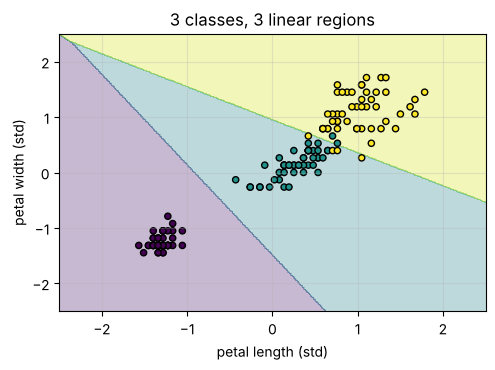

In [11]:
# 🔢 Softmax regression in NumPy
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)   # subtract the max for numerical stability (doesn't change the result)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

class SoftmaxRegressionNP:
    def __init__(self, lr=0.1, epochs=1000):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        n, d = X.shape; K = y.max() + 1
        Y = np.eye(K)[y]                        # one-hot: class 2 → [0, 0, 1]
        self.W, self.b = np.zeros((d, K)), np.zeros(K)
        for _ in range(self.epochs):
            P = softmax(X @ self.W + self.b)
            self.W -= self.lr * X.T @ (P - Y) / n
            self.b -= self.lr * (P - Y).mean(axis=0)
        return self
    def predict_proba(self, X):
        return softmax(X @ self.W + self.b)
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

from sklearn.datasets import load_iris
Xi, yi = load_iris(return_X_y=True)
Xi2 = StandardScaler().fit_transform(Xi[:, 2:])           # petal length & width only, so we can plot
sm = SoftmaxRegressionNP().fit(Xi2, yi)
print("our softmax train accuracy:", np.mean(sm.predict(Xi2) == yi))
print("sklearn train accuracy:   ", LogisticRegression().fit(Xi2, yi).score(Xi2, yi))

x0, x1 = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
plt.contourf(x0, x1, sm.predict(np.c_[x0.ravel(), x1.ravel()]).reshape(x0.shape), alpha=0.3, cmap="viridis")
plt.scatter(Xi2[:, 0], Xi2[:, 1], c=yi, edgecolor="k", cmap="viridis", s=20)
plt.xlabel("petal length (std)"); plt.ylabel("petal width (std)"); plt.title("3 classes, 3 linear regions"); plt.show()

## 8. Pitfalls
- **Scale your features** — gradient descent and regularisation both depend on it.
- **Perfect separation:** if a line separates classes perfectly, unregularised weights grow forever (the loss keeps creeping toward 0). Regularisation fixes it — that's one reason sklearn regularises by default.
- **Class imbalance:** with 99% negatives, predicting "always negative" is 99% accurate and useless. Use `class_weight="balanced"` and better metrics (notebook 03).
- **Probabilities aren't automatically trustworthy** after heavy regularisation or resampling — check **calibration**.

## 9. Key takeaways
- Logistic regression = linear score → **sigmoid** → probability.
- Trained by minimising **log-loss**; gradient = (p − y)·x.
- It's a **linear classifier**; add features for curved boundaries.
- Multi-class → **softmax** + cross-entropy.

## 10. Exercises
1. Odds interpretation: with `w_py` from Section 4, by what factor do the odds of passing multiply per extra hour of study? (Answer: $e^w$.)
2. Train `LogisticRegressionNP` on the moons data without polynomial features, then with your own hand-made features `[x1, x2, x1**2, x2**2, x1*x2]`. Compare accuracy.
3. Remove the max-subtraction line in `softmax` and call it on `np.array([[1000., 1001.]])`. What breaks, and why?

In [12]:
# Exercise 1 — solution
print(f"each extra hour multiplies the odds of passing by e^w = {math.exp(w_py[0]):.2f}x")

# Exercise 3 — solution
Z = np.array([[1000.0, 1001.0]])
with np.errstate(over="ignore", invalid="ignore"):
    print("naive:  ", np.exp(Z) / np.exp(Z).sum())          # inf/inf = nan
print("stable: ", softmax(Z))

each extra hour multiplies the odds of passing by e^w = 3.86x
naive:   [[nan nan]]
stable:  [[0.26894142 0.73105858]]


**Next:** [03 · Model Evaluation](03_model_evaluation.ipynb) — how to tell whether a model is actually good.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §3.3 · `DL_Interview_Notes.md` §1.2 (the sigmoid/softmax gradient cancellation) · `Probability_Statistics_Notes.md` §3.2 (maximum likelihood) · code: `ml_from_scratch.py` → `LogisticRegression`, `SoftmaxRegression`.